<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Histogram**


Estimated time needed: **45** minutes


In this lab, you will focus on the visualization of data. The dataset will be provided through an RDBMS, and you will need to use SQL queries to extract the required data.


## Objectives


In this lab, you will perform the following:


- Visualize the distribution of data using histograms.

- Visualize relationships between features.

- Explore data composition and comparisons.


## Demo: Working with database


#### Download the database file.


In [1]:
# The original `!wget` magic command only runs in Jupyter/Linux environments.
# It is kept below as a comment. Use urllib instead so it works in plain VS Code.
# !wget -O survey-data.sqlite https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/QR9YeprUYhOoLafzlLspAw/survey-results-public.sqlite
import os
import urllib.request
import urllib.error

sqlite_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/QR9YeprUYhOoLafzlLspAw/survey-results-public.sqlite'
sqlite_file = 'survey-data.sqlite'
if not (os.path.exists(sqlite_file) and os.path.getsize(sqlite_file) > 0):
    print('Downloading survey-data.sqlite (this may take a while)...')
    urllib.request.urlretrieve(sqlite_url, sqlite_file)
print('SQLite DB ready at:', os.path.abspath(sqlite_file))

SQLite DB ready at: c:\Users\Jerome\github-jtgreta\ibm-data-analyst\09-ibm-data-analyst-capstone-project\survey-data.sqlite


#### Install the required libraries and import them


In [2]:
# The original `!pip install` magic commands only run in Jupyter environments.
# They are kept below as comments. Use subprocess instead so the packages are
# installed with the same Python interpreter that is selected in VS Code.
# !pip install pandas
import importlib.util
import subprocess
import sys

def install(package, import_name=None):
    """Quietly pip-install a package if it is not already available."""
    import_name = import_name or package
    try:
        spec = importlib.util.find_spec(import_name)
    except (ImportError, ModuleNotFoundError, ValueError):
        spec = None
    if spec is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', package])

install('pandas', 'pandas')
install('matplotlib', 'matplotlib')

In [3]:
# The original `!pip install matplotlib` magic command only runs in Jupyter
# environments. It is kept below as a comment; matplotlib is installed by
# the installer in the cell above so it also works in plain VS Code.
# !pip install matplotlib

In [4]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

#### Connect to the SQLite database


In [5]:
conn = sqlite3.connect('survey-data.sqlite')

## Demo: Basic SQL queries

**Demo 1: Count the number of rows in the table**


In [6]:
QUERY = "SELECT COUNT(*) FROM main"
# df = pd.read_sql_query(QUERY, conn)   # original (overwrote df)
count_df = pd.read_sql_query(QUERY, conn)
print(count_df)

   COUNT(*)
0     65437


**Demo 2: List all tables**


In [7]:
QUERY = """
SELECT name as Table_Name 
FROM sqlite_master 
WHERE type = 'table'
"""
pd.read_sql_query(QUERY, conn)


,Table_Name
0,main


**Demo 3: Group data by age**


In [8]:
QUERY = """
SELECT Age, COUNT(*) as count 
FROM main 
GROUP BY Age 
ORDER BY Age
"""
df_age = pd.read_sql_query(QUERY, conn)
print(df_age)


                  Age  count
0     18-24 years old  14098
1     25-34 years old  23911
2     35-44 years old  14942
3     45-54 years old   6249
4     55-64 years old   2575
5   65 years or older    772
6   Prefer not to say    322
7  Under 18 years old   2568


## Hands-on Lab: Visualizing Data with Histograms


### 1. Visualizing the distribution of data (Histograms)


**1.1 Histogram of `CompTotal` (Total Compensation)**


Objective: Plot a histogram of `CompTotal` to visualize the distribution of respondents' total compensation.


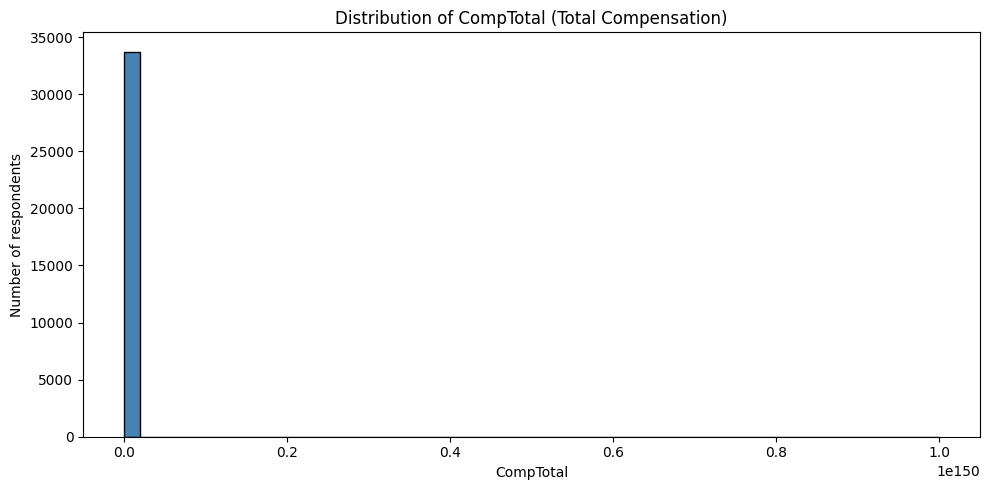

In [9]:
## Write your code here
# 1.1 Histogram of CompTotal (Total Compensation)
QUERY = "SELECT CompTotal FROM main WHERE CompTotal IS NOT NULL"
comp_df = pd.read_sql_query(QUERY, conn)

plt.figure(figsize=(10, 5))
comp_df['CompTotal'].plot(kind='hist', bins=50, color='steelblue', edgecolor='black')
plt.title('Distribution of CompTotal (Total Compensation)')
plt.xlabel('CompTotal')
plt.ylabel('Number of respondents')
plt.tight_layout()
plt.show()

table_name = 'main'

QUERY = """
SELECT sql FROM sqlite_master 
WHERE name= '{}'
""".format(table_name)

# df = pd.read_sql_query(QUERY, conn)   # original (overwrote df)
schema_df = pd.read_sql_query(QUERY, conn)
print(schema_df.iat[0, 0])

Objective: Plot a histogram of `YearsCodePro` to analyze the distribution of coding experience among respondents.


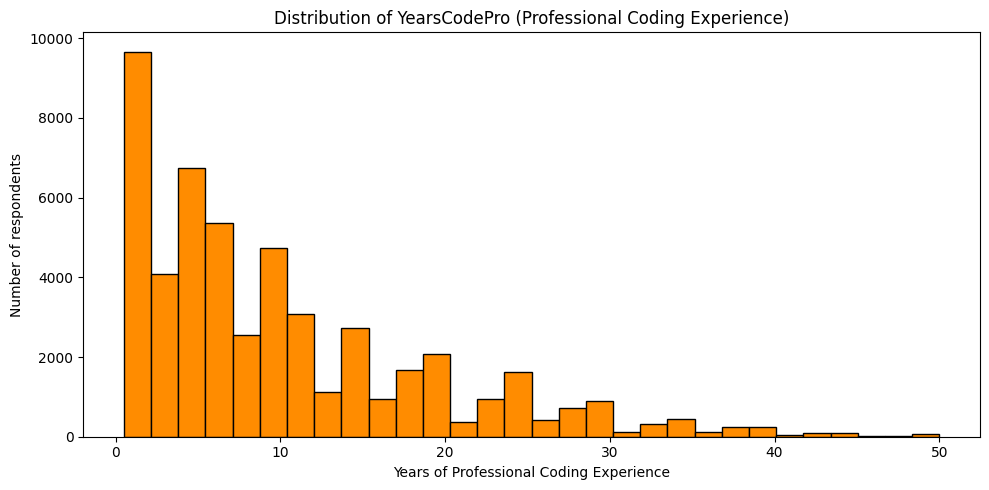

In [10]:
## Write your code here
# 1.2 Histogram of YearsCodePro (Years of Professional Coding Experience)
QUERY = "SELECT YearsCodePro FROM main WHERE YearsCodePro IS NOT NULL"
ycp_df = pd.read_sql_query(QUERY, conn)

# Convert string values ('Less than 1 year', 'More than 50 years') to numeric
def to_years(val):
    if val == 'Less than 1 year':
        return 0.5
    if val == 'More than 50 years':
        return 50
    try:
        return float(val)
    except (ValueError, TypeError):
        return None

ycp_df['YearsCodePro_num'] = ycp_df['YearsCodePro'].apply(to_years)
ycp_df = ycp_df.dropna(subset=['YearsCodePro_num'])

plt.figure(figsize=(10, 5))
ycp_df['YearsCodePro_num'].plot(kind='hist', bins=30, color='darkorange', edgecolor='black')
plt.title('Distribution of YearsCodePro (Professional Coding Experience)')
plt.xlabel('Years of Professional Coding Experience')
plt.ylabel('Number of respondents')
plt.tight_layout()
plt.show()

### 2. Visualizing Relationships in Data


**2.1 Histogram Comparison of `CompTotal` by `Age` Group**


Objective: Use histograms to compare the distribution of CompTotal across different Age groups.


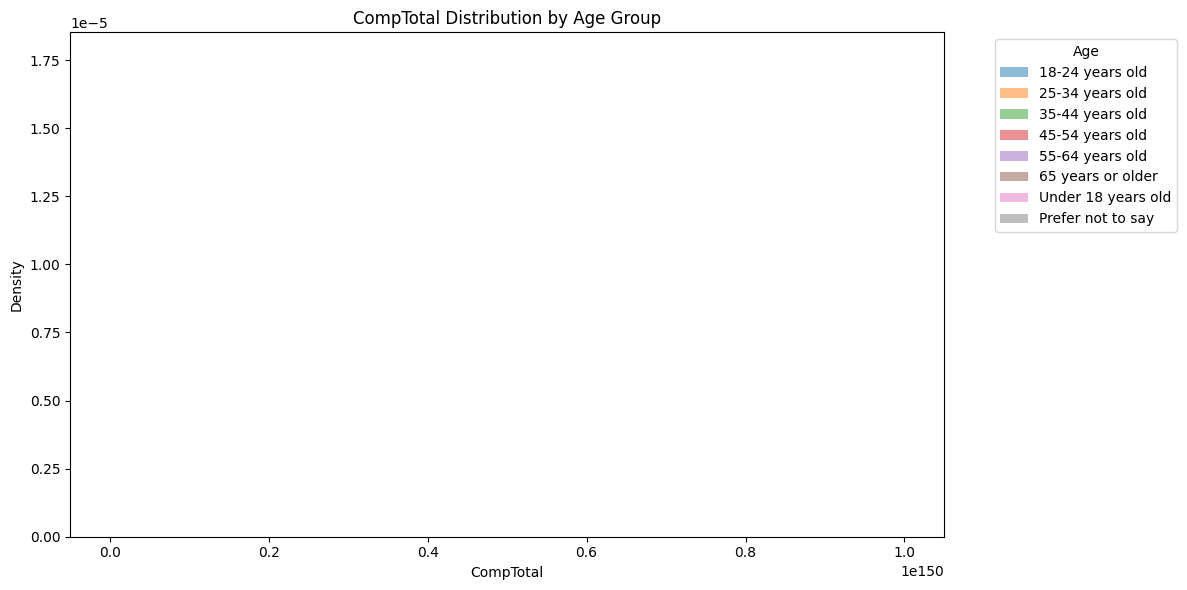

In [11]:
## Write your code here
# 2.1 Histogram Comparison of CompTotal by Age Group
QUERY = "SELECT Age, CompTotal FROM main WHERE CompTotal IS NOT NULL"
age_comp_df = pd.read_sql_query(QUERY, conn)

age_groups = age_comp_df['Age'].unique()
plt.figure(figsize=(12, 6))
for age in age_groups:
    subset = age_comp_df[age_comp_df['Age'] == age]['CompTotal']
    subset.plot(kind='hist', bins=40, alpha=0.5, label=age, density=True)
plt.title('CompTotal Distribution by Age Group')
plt.xlabel('CompTotal')
plt.ylabel('Density')
plt.legend(title='Age', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

**2.2 Histogram of TimeSearching for Different Age Groups**


Objective: Use histograms to explore the distribution of `TimeSearching` (time spent searching for information) for respondents across different age groups.


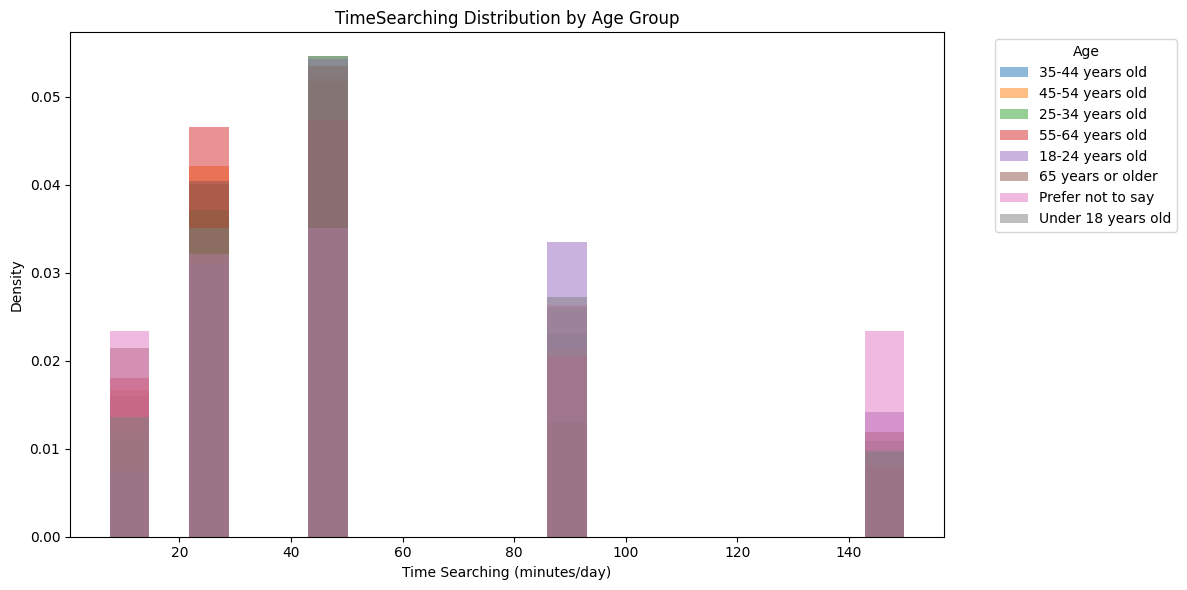

In [12]:
## Write your code here
# 2.2 Histogram of TimeSearching for Different Age Groups
QUERY = "SELECT Age, TimeSearching FROM main WHERE TimeSearching IS NOT NULL"
age_ts_df = pd.read_sql_query(QUERY, conn)

time_map = {
    'Less than 15 minutes a day': 7.5,
    '15-30 minutes a day': 22.5,
    '30-60 minutes a day': 45,
    '60-120 minutes a day': 90,
    'Over 120 minutes a day': 150,
}
age_ts_df['TimeMin'] = age_ts_df['TimeSearching'].map(time_map)
age_ts_df = age_ts_df.dropna(subset=['TimeMin'])

age_groups = age_ts_df['Age'].unique()
plt.figure(figsize=(12, 6))
for age in age_groups:
    subset = age_ts_df[age_ts_df['Age'] == age]['TimeMin']
    subset.plot(kind='hist', bins=20, alpha=0.5, label=age, density=True)
plt.title('TimeSearching Distribution by Age Group')
plt.xlabel('Time Searching (minutes/day)')
plt.ylabel('Density')
plt.legend(title='Age', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### 3. Visualizing the Composition of Data


**3.1 Histogram of Most Desired Databases (`DatabaseWantToWorkWith`)**


Objective: Visualize the most desired databases for future learning using a histogram of the top 5 databases.


DatabaseWantToWorkWith
PostgreSQL    24005
SQLite        13489
MySQL         12269
MongoDB       10982
Redis         10847
Name: count, dtype: int64


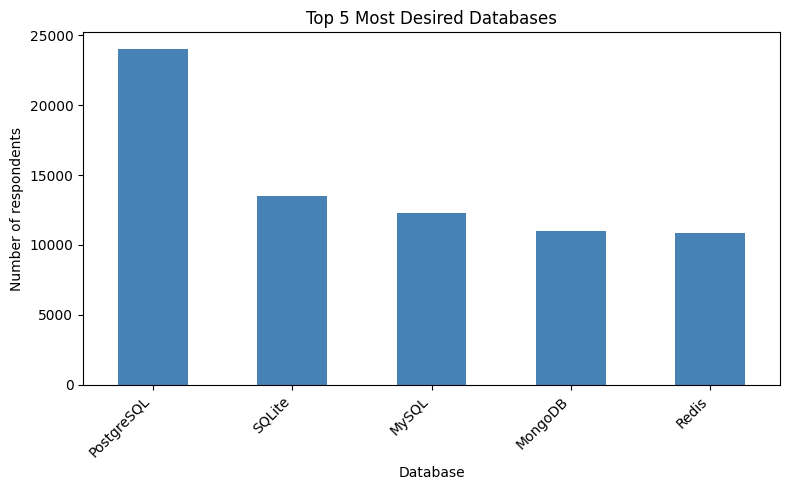

In [13]:
## Write your code here
# 3.1 Histogram of Most Desired Databases (DatabaseWantToWorkWith)
QUERY = "SELECT DatabaseWantToWorkWith FROM main WHERE DatabaseWantToWorkWith IS NOT NULL"
db_df = pd.read_sql_query(QUERY, conn)

db_counts = db_df['DatabaseWantToWorkWith'].str.split(';').explode().value_counts().head(5)
print(db_counts)

plt.figure(figsize=(8, 5))
db_counts.plot(kind='bar', color='steelblue')
plt.title('Top 5 Most Desired Databases')
plt.xlabel('Database')
plt.ylabel('Number of respondents')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**3.2 Histogram of Preferred Work Locations (`RemoteWork`)**


Objective: Use a histogram to explore the distribution of preferred work arrangements (`remote work`).


RemoteWork
Hybrid (some remote, some in-person)    23015
Remote                                  20831
In-person                               10960
Name: count, dtype: int64


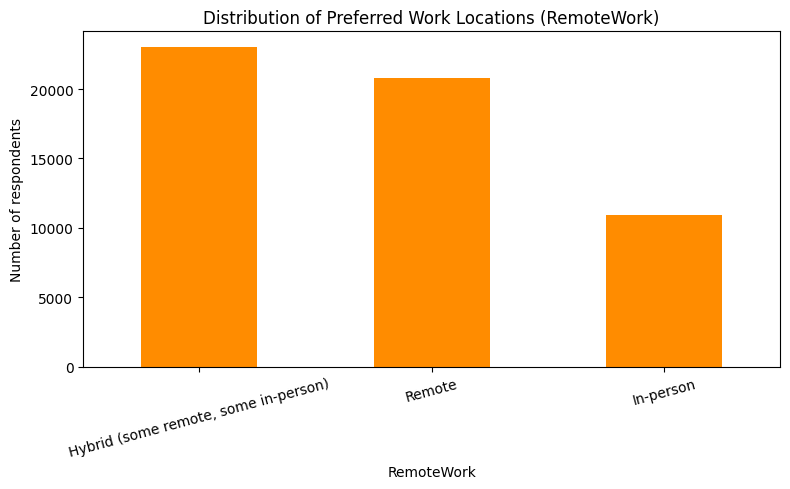

In [14]:
## Write your code here
# 3.2 Histogram of Preferred Work Locations (RemoteWork)
QUERY = "SELECT RemoteWork FROM main WHERE RemoteWork IS NOT NULL"
rw_df = pd.read_sql_query(QUERY, conn)

rw_counts = rw_df['RemoteWork'].value_counts()
print(rw_counts)

plt.figure(figsize=(8, 5))
rw_counts.plot(kind='bar', color='darkorange')
plt.title('Distribution of Preferred Work Locations (RemoteWork)')
plt.xlabel('RemoteWork')
plt.ylabel('Number of respondents')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### 4. Visualizing Comparison of Data


**4.1 Histogram of Median CompTotal for Ages 45 to 60**


Objective: Plot the histogram for `CompTotal` within the age group 45 to 60 to analyze compensation distribution among mid-career respondents.


Age
45-54 years old    130000.0
55-64 years old    135000.0
Name: CompTotal, dtype: float64


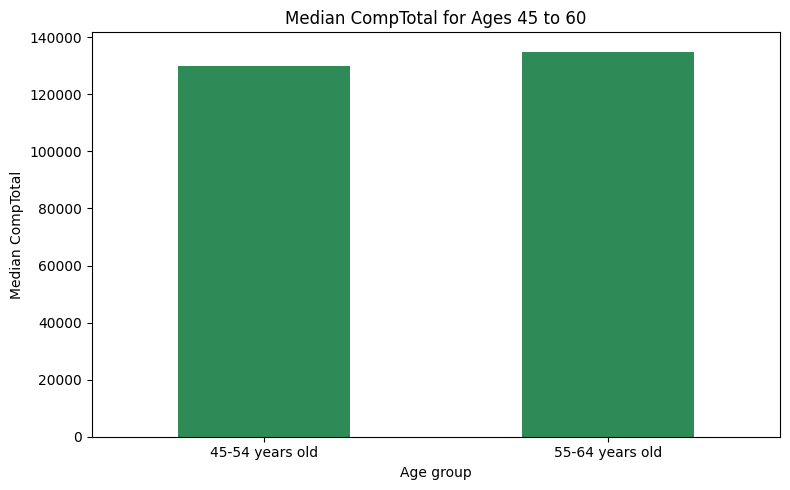

In [15]:
## Write your code here
# 4.1 Histogram of Median CompTotal for Ages 45 to 60
QUERY = "SELECT Age, CompTotal FROM main WHERE Age IN ('45-54 years old', '55-64 years old') AND CompTotal IS NOT NULL"
comp_age_df = pd.read_sql_query(QUERY, conn)

median_comp = comp_age_df.groupby('Age')['CompTotal'].median()
print(median_comp)

plt.figure(figsize=(8, 5))
median_comp.plot(kind='bar', color='seagreen')
plt.title('Median CompTotal for Ages 45 to 60')
plt.xlabel('Age group')
plt.ylabel('Median CompTotal')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**4.2 Histogram of Job Satisfaction (`JobSat`) by YearsCodePro**


Objective: Plot the histogram for `JobSat` scores based on respondents' years of professional coding experience.


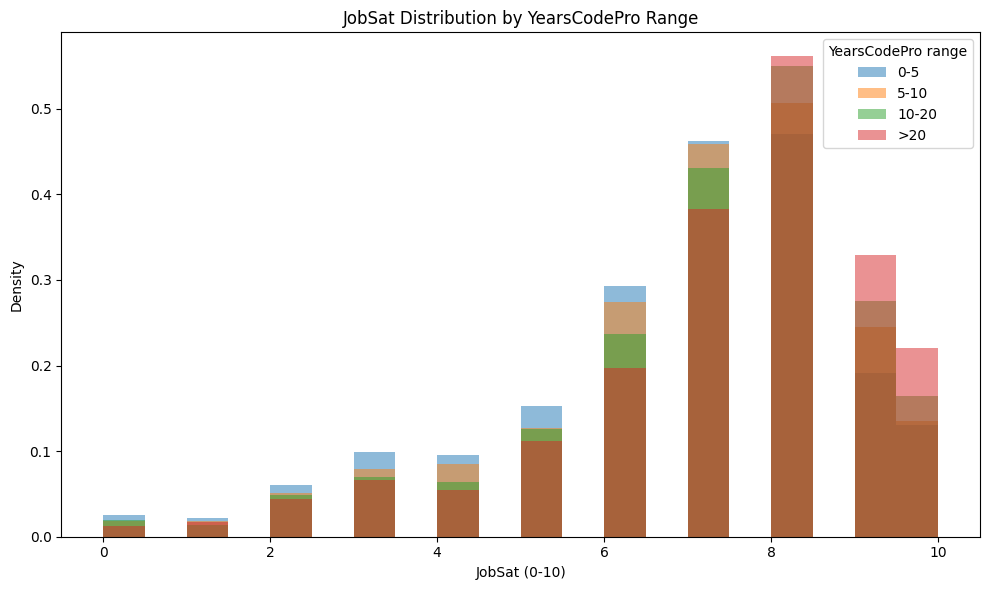

In [16]:
## Write your code here
# 4.2 Histogram of JobSat by YearsCodePro
QUERY = "SELECT YearsCodePro, JobSat FROM main WHERE JobSat IS NOT NULL"
js_ycp_df = pd.read_sql_query(QUERY, conn)

def to_years(val):
    if val == 'Less than 1 year':
        return 0.5
    if val == 'More than 50 years':
        return 50
    try:
        return float(val)
    except (ValueError, TypeError):
        return None

js_ycp_df['YearsCodePro_num'] = js_ycp_df['YearsCodePro'].apply(to_years)
js_ycp_df = js_ycp_df.dropna(subset=['YearsCodePro_num'])

# Bin YearsCodePro into ranges for comparison
bins = [0, 5, 10, 20, 100]
labels = ['0-5', '5-10', '10-20', '>20']
js_ycp_df['ExpRange'] = pd.cut(js_ycp_df['YearsCodePro_num'], bins=bins, labels=labels, right=False)

plt.figure(figsize=(10, 6))
for rng in labels:
    subset = js_ycp_df[js_ycp_df['ExpRange'] == rng]['JobSat']
    subset.plot(kind='hist', bins=20, alpha=0.5, label=rng, density=True)
plt.title('JobSat Distribution by YearsCodePro Range')
plt.xlabel('JobSat (0-10)')
plt.ylabel('Density')
plt.legend(title='YearsCodePro range')
plt.tight_layout()
plt.show()

### Final step: Close the database connection


Once you've completed the lab, make sure to close the connection to the SQLite database:



In [17]:
conn.close()

### Summary


In this lab, you used histograms to visualize various aspects of the dataset, focusing on:

- Distribution of compensation, coding experience, and work hours.

- Relationships in compensation across age groups and work status.

- Composition of data by desired databases and work environments.

- Comparisons of job satisfaction across years of experience.

Histograms helped reveal patterns and distributions in the data, enhancing your understanding of developer demographics and preferences.


## Authors:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


Copyright © IBM Corporation. All rights reserved.
